# **09. Model Tuning**

In [34]:
# Import Libraries

import sys
sys.path.append("..")
from src.utilis import *

from pathlib import Path
import pickle
import joblib
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder, FunctionTransformer, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression
from sklearn.metrics import make_scorer, mean_squared_error, mean_absolute_error, r2_score

%matplotlib inline

sns.set_style('darkgrid')


In [16]:
# define file path for processed data
parent_path = Path.cwd().parent
file_path = parent_path.joinpath("models", "processed.pkl")


In [17]:
# Load the processed data from the previous step
print(f"Loading processed data...")
with open(file_path, "rb") as f:
    processed_data = pickle.load(f)

Loading processed data...


In [18]:
processed_data.keys()


dict_keys(['X_train', 'y_train', 'X_test', 'test_id', 'numeric_features', 'ordinal_features', 'categorical_features', 'boolean_features', 'year_features'])

In [19]:
# Extract features and target variable
X_train = processed_data["X_train"]
y_train = processed_data["y_train"]
X_test = processed_data["X_test"]
numeric_feat = processed_data["numeric_features"]
ordinal_feat = processed_data["ordinal_features"]
categorical_feat = processed_data["categorical_features"]
boolean_feat = processed_data["boolean_features"]
year_feat = processed_data["year_features"]
test_id = processed_data['test_id']
total_numeric_features = ordinal_feat + numeric_feat + year_feat + boolean_feat



In [20]:
print(f"Training data shape: {X_train.shape}")
print(f"Test data shape: {X_test.shape}")


Training data shape: (1459, 21)
Test data shape: (1457, 21)


In [21]:
# Load the best model info from baseline
best_file_path = parent_path.joinpath('models', 'best_model.pkl')
try:
    print("Loading best model from baseline step...")
    with open(best_file_path, 'rb') as f:
        best_baseline_model = joblib.load(f)

    # use the model class from baseline to determine which model to tune
    if hasattr(best_baseline_model, 'named_steps'):
        model_class = best_baseline_model.named_steps['model'].__class__.__name__
    else:
        model_class = best_baseline_model.__class__.__name__
    print(f"Best model from baseline: {model_class}")
    
except:
    print("No best model file found from baseline. Using Ridge and Lasso as default.")
    model_class = 'Ridge'  # Default to Ridge if no best model found

Loading best model from baseline step...
Best model from baseline: Ridge


## **1. Setting up Preprocessing Pipeline**

In [22]:
print("\n=== SETTING UP PREPROCESSING PIPELINE ===")

# For numeric features: impute and scale
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# For categorical features: impute and one-hot encoding
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy='most_frequent')),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# For boolean features: convert into integer
boolean_transformer = Pipeline(steps=[
    ("bool", OrdinalEncoder(dtype=int))
])

# For year and ordinal features: use them as raw
year_transformer = Pipeline(steps=[
    ("passthrough", "passthrough")
])

ordinal_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

# Combining processing steps
transformers = [("numeric", numeric_transformer, total_numeric_features),
                # ("boolean", boolean_transformer, boolean_feat),
                # ("ordinal", ordinal_transformer, ordinal_feat),
                # ("year", year_transformer, year_feat)

]

# Add categorical transformer if there is categorical feature:
if len(categorical_feat) > 0:
    transformers.append(("cat", categorical_transformer, categorical_feat))

preprocessor = ColumnTransformer(transformers=transformers)




=== SETTING UP PREPROCESSING PIPELINE ===


## **2. Hyperparameter Tuning for Ridge Regression**

In [23]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score, KFold
print("\n=== HYPERPARAMETER TUNING ===")

# store tuning results in dictionary
tuning_results = {}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Elasticnet Regression
if model_class in ['ElasticNet', 'LinearRegression']:
    print("\n1. Detailed ElasticNet Tuning")
    
    elasticnet_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', ElasticNet(max_iter=10000))
    ])
    elasticnet_param_grid = {
        'model__alpha': np.logspace(-4, 0, 10),
        'model__l1_ratio': np.linspace(0.1, 0.9, 9)
    }
    
    elasticnet_grid = GridSearchCV(
        elasticnet_pipeline,
        elasticnet_param_grid,
        cv=cv,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1,
        verbose=1
    )
    
    elasticnet_grid.fit(X_train, y_train)
    
    print(f"Best ElasticNet alpha: {elasticnet_grid.best_params_['model__alpha']:.6f}")
    print(f"Best ElasticNet l1_ratio: {elasticnet_grid.best_params_['model__l1_ratio']:.2f}")
    print(f"Best ElasticNet CV RMSE: ${-elasticnet_grid.best_score_:.2f}")
    
    tuning_results['ElasticNet'] = {
        'best_params': elasticnet_grid.best_params_,
        'cv_rmse': -elasticnet_grid.best_score_,
        'model': elasticnet_grid.best_estimator_
    }

# Ridge Regression Tuning
if model_class in ["Ridge", "LinearRegression"]:
    print("\n2. Detailed Ridge Regression Tuning")
    
    ridge_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', Ridge())
    ])
    
    ridge_param_grid = {'model__alpha': np.linspace(8, 20, 15)}
    
    ridge_grid = GridSearchCV(
        ridge_pipeline,
        ridge_param_grid,
        cv=cv,
        scoring='neg_root_mean_squared_error',
        n_jobs=1,
        verbose=1
    )
    
    ridge_grid.fit(X_train, y_train)
    
    print(f"Best Ridge alpha: {ridge_grid.best_params_['model__alpha']:.4f}")
    print(f"Best Ridge CV RMSE: ${-ridge_grid.best_score_:.2f}")
    
    tuning_results['Ridge'] = {
        'best_params': ridge_grid.best_params_,
        'cv_rmse': -ridge_grid.best_score_,
        'model': ridge_grid.best_estimator_
    }

# Lasso Regression Tuning( if applicable)
if model_class == "Lasso":
    print("\n3. Detailed Lasso Regression Tuning")
    
    lasso_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', Lasso(max_iter=10000))
    ])
    
    lasso_param_grid = {'model__alpha': np.logspace(-4, 0, 100)}
    
    lasso_grid = GridSearchCV(
        lasso_pipeline,
        lasso_param_grid,
        cv=cv,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1,
        verbose=1
    )
    
    lasso_grid.fit(X_train, y_train)
    
    print(f"Best Lasso alpha: {lasso_grid.best_params_['model__alpha']:.6f}")
    print(f"Best Lasso CV RMSE: ${-lasso_grid.best_score_:.2f}")
    
    tuning_results['Lasso'] = {
        'best_params': lasso_grid.best_params_,
        'cv_rmse': -lasso_grid.best_score_,
        'model': lasso_grid.best_estimator_
    }
    


=== HYPERPARAMETER TUNING ===

2. Detailed Ridge Regression Tuning
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best Ridge alpha: 20.0000
Best Ridge CV RMSE: $34501.56


In [24]:
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, make_scorer
from sklearn.linear_model import Ridge, ElasticNet, Lasso

print("\n=== HYPERPARAMETER TUNING ===")

tuning_results = {}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ---------------------------------------------------------
# RMSE in ORIGINAL SalePrice scale
# ---------------------------------------------------------
# def original_scale_rmse(y_true_log, y_pred_log):
#     y_true = np.expm1(y_true_log)
#     y_pred = np.expm1(y_pred_log)

#     return np.sqrt(
#         mean_squared_error(y_true, y_pred)
#     )


# rmse_scorer = make_scorer(
#     original_scale_rmse,
#     greater_is_better=False
# )


# =========================================================
# ElasticNet
# =========================================================
if model_class in ['ElasticNet', 'LinearRegression']:

    print("\n1. Detailed ElasticNet Tuning")

    elasticnet_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', ElasticNet(max_iter=10000))
    ])

    elasticnet_param_grid = {
        'model__alpha': np.logspace(-4, 0, 10),
        'model__l1_ratio': np.linspace(0.1, 0.9, 9)
    }

    elasticnet_grid = GridSearchCV(
        elasticnet_pipeline,
        elasticnet_param_grid,
        cv=cv,
        scoring='neg_root_mean_squared_error',
        n_jobs=1,
        verbose=1
    )

    elasticnet_grid.fit(
        X_train,
        y_train
    )

    elasticnet_cv_rmse = -elasticnet_grid.best_score_

    print(
        f"Best ElasticNet alpha: "
        f"{elasticnet_grid.best_params_['model__alpha']:.6f}"
    )

    print(
        f"Best ElasticNet l1_ratio: "
        f"{elasticnet_grid.best_params_['model__l1_ratio']:.2f}"
    )

    print(
        f"Best ElasticNet CV RMSE: "
        f"${elasticnet_cv_rmse:,.2f}"
    )

    tuning_results['ElasticNet'] = {
        'best_params': elasticnet_grid.best_params_,
        'cv_rmse': elasticnet_cv_rmse,
        'model': elasticnet_grid.best_estimator_
    }


# =========================================================
# Ridge
# =========================================================
if model_class in ["Ridge", "LinearRegression"]:

    print("\n2. Detailed Ridge Regression Tuning")

    ridge_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', Ridge(max_iter=10000))
    ])

    ridge_param_grid = {
        'model__alpha': np.logspace(-4, 2, 150)
    }

    ridge_grid = GridSearchCV(
        ridge_pipeline,
        ridge_param_grid,
        cv=cv,
        scoring='neg_root_mean_squared_error',
        n_jobs=1,
        verbose=1
    )

    ridge_grid.fit(
        X_train,
        y_train
    )

    ridge_cv_rmse = -ridge_grid.best_score_

    print(
        f"Best Ridge alpha: "
        f"{ridge_grid.best_params_['model__alpha']:.4f}"
    )

    print(
        f"Best Ridge CV RMSE: "
        f"${ridge_cv_rmse:,.2f}"
    )

    tuning_results['Ridge'] = {
        'best_params': ridge_grid.best_params_,
        'cv_rmse': ridge_cv_rmse,
        'model': ridge_grid.best_estimator_
    }


# =========================================================
# Lasso
# =========================================================
if model_class == "Lasso":

    print("\n3. Detailed Lasso Regression Tuning")

    lasso_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', Lasso(max_iter=10000))
    ])

    lasso_param_grid = {
        'model__alpha': np.logspace(-4, 0, 100)
    }

    lasso_grid = GridSearchCV(
        lasso_pipeline,
        lasso_param_grid,
        cv=cv,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1,
        verbose=1
    )

    lasso_grid.fit(
        X_train,
        y_train
    )

    lasso_cv_rmse = -lasso_grid.best_score_

    print(
        f"Best Lasso alpha: "
        f"{lasso_grid.best_params_['model__alpha']:.6f}"
    )

    print(
        f"Best Lasso CV RMSE: "
        f"${lasso_cv_rmse:,.2f}"
    )

    tuning_results['Lasso'] = {
        'best_params': lasso_grid.best_params_,
        'cv_rmse': lasso_cv_rmse,
        'model': lasso_grid.best_estimator_
    }



=== HYPERPARAMETER TUNING ===

2. Detailed Ridge Regression Tuning
Fitting 5 folds for each of 150 candidates, totalling 750 fits
Best Ridge alpha: 100.0000
Best Ridge CV RMSE: $33,601.80


## **3. Compared Tuned Models**


=== COMPARING TUNED MODELS ===


,model,cv_rmse,parameters
0,Ridge,33601.80,{'model__alpha': 100.0}


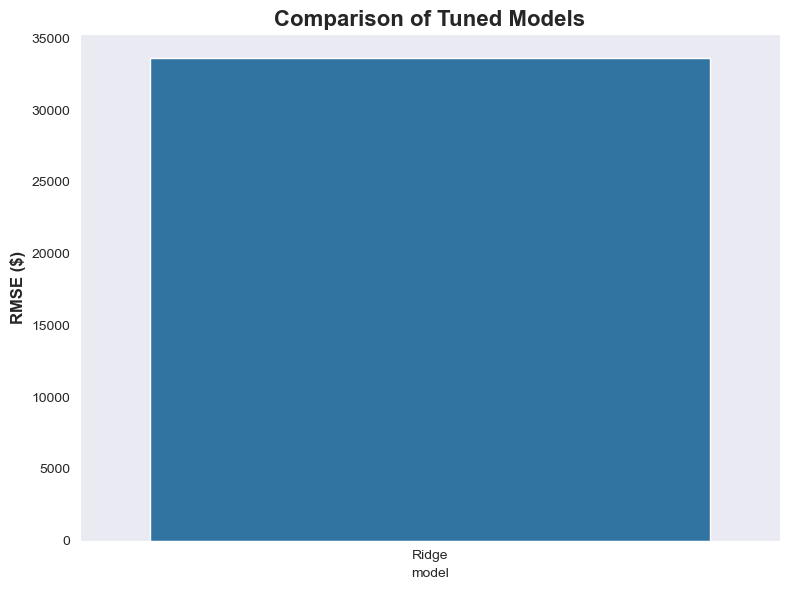

In [25]:
print("\n=== COMPARING TUNED MODELS ===")

# Create comparison DataFrame
tuned_df = pd.DataFrame({
    'model': list(tuning_results.keys()),
    'cv_rmse': [tuning_results[t]['cv_rmse'] for t in tuning_results],
    'parameters': [str(tuning_results[t]['best_params']) for t in tuning_results]
})

# Sort by CV RMSE
tuned_df = tuned_df.sort_values('cv_rmse')
display(tuned_df)

# Visualize results
plt.figure(figsize=(8, 6))
sns.barplot(x='model', y='cv_rmse', data=tuned_df)
plt.title('Comparison of Tuned Models', fontsize=16, fontweight='bold')
plt.ylabel('RMSE ($)', fontsize=12, fontweight='bold')
plt.grid(axis='y')

plt.tight_layout()
plt.show()


## **4. Selecting Final Model and Saving**

In [26]:
tuned_df

,model,cv_rmse,parameters
0,Ridge,33601.80,{'model__alpha': 100.0}


In [27]:
best_model_name = tuned_df.iloc[0]['model']
best_params = tuning_results[best_model_name]['best_params']
best_rmse = tuning_results[best_model_name]['cv_rmse']
best_model = tuning_results[best_model_name]['model']

print(f"\n=== BEST MODEL ===")
print(f"Model: {best_model_name}")
print(f"Parameters: {best_params}")
print(f"CV RMSE: ${best_rmse:.2f}")
print(f"")

try:
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    prev_scores = cross_val_score(best_baseline_model, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')
    prev_rmse = -prev_scores.mean()
    
    improvement = prev_rmse - best_rmse
    percent_improvement = (improvement / prev_rmse) * 100
    
    print(f"Baseline RMSE: ${prev_rmse:.2f}")
    print(f"Tuned RMSE: ${best_rmse:.2f}")
    print(f"Improvement: ${improvement:.2f} ({percent_improvement:.2f}%)")
    
except:
    print("\nNo baseline model found for comparison.")



=== BEST MODEL ===
Model: Ridge
Parameters: {'model__alpha': 100.0}
CV RMSE: $33601.80

Baseline RMSE: $33686.40
Tuned RMSE: $33601.80
Improvement: $84.60 (0.25%)


In [ ]:
# Save the final best model in .pkl file for furthur use
model_dir = parent_path.joinpath("models")
model_dir.mkdir(parents=True, exist_ok=True)

# Define file path inside model directory
final_model_file = model_dir.joinpath("final_tuned_model.pkl")

# Save the final tuned model
with open(final_model_file, 'wb') as f:
    joblib.dump(best_model, f)

print("Final tuned model saved successfully!!!!")

Final tuned model saved successfully!!!!


In [29]:
# Load it back to verify
with open(final_model_file, 'rb') as f:
    model = joblib.load(f)

## **Model Evaluation**

## **5. Selecting Final Model and Saving**

In [30]:
print("\n=== GENERATING PREDICTIONS ===")

test_predictions = best_model.predict(X_test)
final_submission = pd.DataFrame({'Id': test_id, 'SalePrice': test_predictions})
final_submission['SalePrice'] = final_submission['SalePrice'].clip(lower=0)
final_submission.to_csv(parent_path.joinpath("submission", "final_submission.csv"), index=False)

print("Final submission file created successfully!")


=== GENERATING PREDICTIONS ===
Final submission file created successfully!


In [31]:
final_submission.head()

,Id,SalePrice
0,1461,110743.86
1,1462,162216.12
2,1463,174972.19
3,1464,193778.12
4,1465,232895.54


In [32]:
print("="*40, "COMPLETED", "="*40)

======================================== COMPLETED ========================================
